# 09 · Audit label dan diagnostik metadata MAUDE MRI

Notebook 08 hanya memakai narasi `event_text`. Data mentah openFDA (`data/raw/maude_LNH_raw.jsonl`) memuat sekitar 90 kolom lain, misalnya outcome pasien, kode masalah pasien dan produk, flag, umur, dan pelapor. Notebook ini menjawab empat pertanyaan:

| Bagian | Pertanyaan | Keluaran utama |
|---|---|---|
| 2 | Kolom mana yang terisi, dan mana yang **bocor label**? | `09_inventaris_kolom.csv` |
| 3 | Seberapa kuat `patient_outcome` menentukan `event_type`? | `09_outcome_x_event_type.csv` |
| 4–5 | Apakah kode pelapor saling **tidak konsisten**, dan apakah hal itu menjelaskan kesalahan model notebook 08? | `09_inkonsistensi_kode.csv`, `09_kesalahan_vs_inkonsistensi.csv` |
| 6–7 | Mengapa Other dan Death sulit diprediksi? | `09_other_per_era.csv`, `09_death_test.csv` |
| 8 | Laporan mana yang layak ditelaah manusia? (prediksi model disembunyikan) | `09_telaah_buta.csv` dan kuncinya |
| 9 | Apakah metadata bisa menjadi fitur? | `09_diagnostik_metadata.csv` |
| 10 | Seberapa besar efek kebocoran bila `patient_outcome` dimasukkan? (kontrol positif, **bukan** skor resmi) | `09_kontrol_kebocoran.csv` |

**Aturan.**
- Kolom yang diisi pada formulir yang sama dengan `event_type`, atau yang memuat hasil tindak lanjut, **tidak** dijadikan fitur.
- Ketidakcocokan antarkolom hanya menandai laporan untuk **ditelaah**. Ketidakcocokan itu bukan bukti salah label, dan bukan dasar untuk mengganti label secara otomatis.
- MAUDE menampilkan versi laporan terbaru setelah suplemen, jadi data ini tidak menunjukkan kolom mana yang tersedia saat laporan pertama masuk.

## 1. Setup

In [1]:
import json, re, collections
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import fisher_exact
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import f1_score

ROOT = Path("..")
OUT = ROOT / "outputs/nb09"
TAB, FIG = OUT / "tables", OUT / "figures"
for p in (TAB, FIG):
    p.mkdir(parents=True, exist_ok=True)
SEED = 42
KELAS = ["Injury", "Malfunction", "Death", "Other"]
WARNA = {"Injury": "#0072B2", "Malfunction": "#E69F00", "Death": "#333333", "Other": "#009E73"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def bar_labels(ax, fmt="{:.0f}", **kw):
    """Semua bar chart wajib berangka di atas batang."""
    for c in ax.containers:
        ax.bar_label(c, labels=[fmt.format(v) if v == v else "" for v in c.datavalues],
                     padding=2, fontsize=kw.get("fontsize", 8))


def simpan_fig(nama):
    plt.tight_layout()
    plt.savefig(FIG / f"{nama}.png", dpi=150, bbox_inches="tight")
    plt.show()


def simpan_tab(df, nama, **kw):
    df.to_csv(TAB / f"{nama}.csv", **kw)
    return df

### Muat data

- 4.833 rekaman mentah (jsonl)
- 3.604 laporan bersih (`data_eksperimen.csv`, hasil notebook 01–02)
- prediksi test model terbaik notebook 08 (BART-large-MNLI fine-tune, ROS + aug)

In [2]:
rec = {r["mdr_report_key"]: r for r in map(json.loads, open(ROOT / "data/raw/maude_LNH_raw.jsonl", encoding="utf-8"))}
d = pd.read_csv(ROOT / "data/processed/data_eksperimen.csv", keep_default_na=False, dtype=str)
d["tahun"] = d.date_received.str[:4].astype(int); d["fold"] = d.fold.astype(int)
assert len(rec) == 4833 and len(d) == 3604 and d.mdr_report_key.isin(rec.keys()).all()

pred = pd.read_csv(ROOT / "outputs/nb08/predictions/BART_fine-tune_BART-large-MNLI_fine-tune_ROS_aug_bt.csv",
                   dtype={"mdr_report_key": str})
manifest = pd.read_csv(ROOT / "outputs/nb08/tables/05_manifest_test.csv", dtype=str)
assert set(pred.mdr_report_key) == set(manifest.mdr_report_key) and len(pred) == 534
print("rekaman mentah:", len(rec), "| laporan bersih:", len(d), "| test notebook 08:", len(pred))

rekaman mentah: 4833 | laporan bersih: 3604 | test notebook 08: 534


### Ekstraksi kolom dari jsonl

Satu laporan bisa memuat beberapa entri pasien atau perangkat; nilainya digabung. Kode outcome openFDA mengikuti [kamus openFDA](https://github.com/FDA/openfda/blob/master/openfda/maude/data/enums.csv): D = Death, L = Life Threatening, H = Hospitalization, R = Required Intervention, S = Disability, C = Congenital Anomaly, O = Other.

In [3]:
KODE = {"D": "Death", "L": "Life Threatening", "H": "Hospitalization", "R": "Required Intervention",
        "S": "Disability", "C": "Congenital Anomaly", "O": "Other"}
BERAT = {"Life Threatening", "Hospitalization", "Required Intervention", "Disability"}


def bersih(x):
    return [str(v).strip() for v in (x or []) if v not in (None, "") and str(v).strip()]


def ekstrak(r):
    pts = r.get("patient") or [{}]
    dev = (r.get("device") or [{}])[0]
    out = sorted({KODE.get(t, t) for p in pts for t in bersih(p.get("sequence_number_outcome"))})
    teks = r.get("mdr_text") or []
    return dict(
        outcome=";".join(out),
        patient_problems=";".join(sorted({t for p in pts for t in bersih(p.get("patient_problems"))})),
        product_problems=";".join(bersih(r.get("product_problems"))),
        adverse_event_flag=r.get("adverse_event_flag") or "",
        product_problem_flag=r.get("product_problem_flag") or "",
        mfr_narrative=" ".join(t.get("text") or "" for t in teks if "manufacturer" in (t.get("text_type_code") or "").lower()).strip(),
        patient_age=str(pts[0].get("patient_age") or "").strip(),
        patient_sex=str(pts[0].get("patient_sex") or "").strip(),
        event_location=(r.get("event_location") or "").strip(),
        device_operator=(dev.get("device_operator") or "").strip(),
        reporter_occupation=(r.get("reporter_occupation_code") or "").strip(),
        source_type=";".join(bersih(r.get("source_type"))),
        report_source=(r.get("report_source_code") or "").strip(),
        date_of_event=(r.get("date_of_event") or "").strip(),
        remedial_action=";".join(bersih(r.get("remedial_action"))),
    )


semua = pd.DataFrame([dict(mdr_report_key=k, **ekstrak(r)) for k, r in rec.items()])
d = d.merge(semua, on="mdr_report_key", how="left", validate="one_to_one")


def grup_outcome(s):
    t = set(filter(None, s.split(";")))
    if "Death" in t: return "Death"
    if t & BERAT: return "Berat (L/H/R/S)"
    if t == {"Other"}: return "Other saja"
    if t: return "Kode lain"
    return "Kosong"


d["outcome_grup"] = d.outcome.map(grup_outcome)
d["era"] = pd.cut(d.tahun, [0, 2010, 2020, 2100], labels=["s.d. 2010", "2011-2020", "2021+"]).astype(str)
print(d.outcome_grup.value_counts().to_dict())

{'Other saja': 1764, 'Kosong': 1147, 'Berat (L/H/R/S)': 656, 'Death': 35, 'Kode lain': 2}


## 2. Inventaris kolom dan klasifikasi kebocoran

,kolom,kelas,alasan,terisi_mentah,terisi_bersih,persen_bersih
0,outcome,bocor label,outcome Death hampir identik dengan label Death,2561,2457,68.2
1,adverse_event_flag,bocor label,"flag N hampir selalu Malfunction, Y pada semua...",4779,3581,99.4
2,product_problem_flag,bocor label,flag Y hampir selalu Malfunction,4670,3522,97.7
3,patient_problems,audit saja,kode hasil penilaian pelapor; berisi 'Death' d...,4733,3519,97.6
4,product_problems,audit saja,kode hasil penilaian; menandai template (Detac...,4697,3485,96.7
5,mfr_narrative,audit saja,"narasi tindak lanjut pabrikan, bisa memuat has...",3507,2458,68.2
6,remedial_action,analisis saja,"tindakan setelah kejadian, tidak boleh jadi input",1772,793,22.0
7,patient_age,kandidat bersyarat,tidak menentukan label; ketersediaan saat pred...,1969,1861,51.6
8,patient_sex,kandidat bersyarat,idem; sebagian besar Unknown/kosong,510,486,13.5
9,event_location,analisis saja,pola era/kanal pelaporan,470,405,11.2


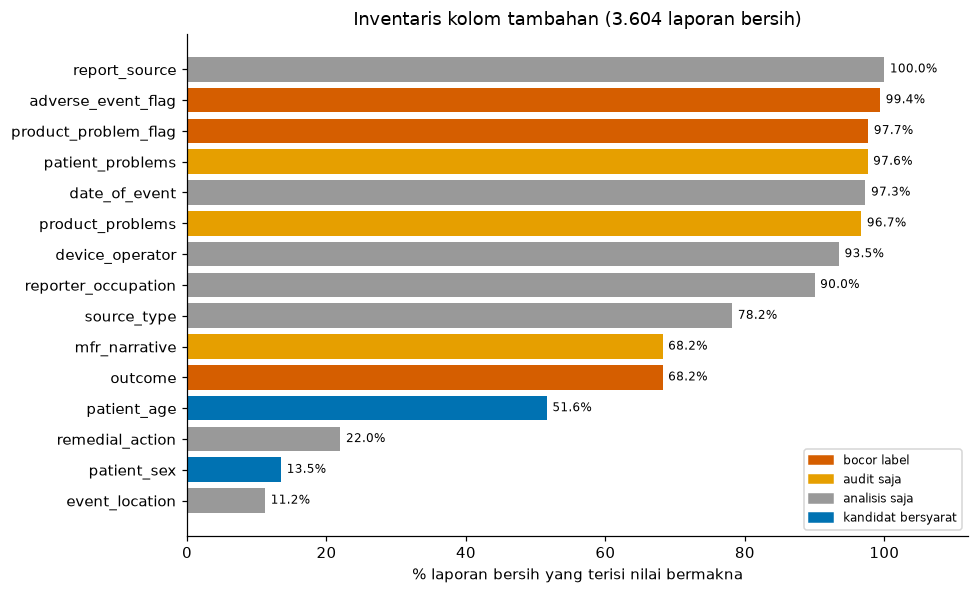

In [4]:
UMUR_SAH = re.compile(r"^\d+(\.\d+)?\s*[A-Za-z]+")
KLAS = {
    "outcome": ("bocor label", "outcome Death hampir identik dengan label Death"),
    "adverse_event_flag": ("bocor label", "flag N hampir selalu Malfunction, Y pada semua Death"),
    "product_problem_flag": ("bocor label", "flag Y hampir selalu Malfunction"),
    "patient_problems": ("audit saja", "kode hasil penilaian pelapor; berisi 'Death' dan 'No Clinical Signs'"),
    "product_problems": ("audit saja", "kode hasil penilaian; menandai template (Detachment)"),
    "mfr_narrative": ("audit saja", "narasi tindak lanjut pabrikan, bisa memuat hasil investigasi"),
    "remedial_action": ("analisis saja", "tindakan setelah kejadian, tidak boleh jadi input"),
    "patient_age": ("kandidat bersyarat", "tidak menentukan label; ketersediaan saat prediksi belum terverifikasi"),
    "patient_sex": ("kandidat bersyarat", "idem; sebagian besar Unknown/kosong"),
    "event_location": ("analisis saja", "pola era/kanal pelaporan"),
    "device_operator": ("analisis saja", "didominasi HEALTH PROFESSIONAL"),
    "reporter_occupation": ("analisis saja", "pola kanal pelaporan"),
    "source_type": ("analisis saja", "pola kanal pelaporan"),
    "report_source": ("analisis saja", "pola kanal pelaporan"),
    "date_of_event": ("analisis saja", "era pelaporan; jalan pintas temporal"),
}


def terisi(s, kolom):
    if kolom == "patient_age":
        return s.str.match(UMUR_SAH)
    if kolom == "patient_sex":
        return s.isin(["Female", "Male"])
    return s.ne("") & ~s.str.upper().isin(["NA", "N/A", "UNKNOWN", "UNK", "*", "NONE", "I", "INVALID DATA", "NO INFORMATION"])


inv = pd.DataFrame([dict(kolom=k, kelas=v[0], alasan=v[1],
                         terisi_mentah=int(terisi(semua[k], k).sum()),
                         terisi_bersih=int(terisi(d[k], k).sum()),
                         persen_bersih=round(100 * terisi(d[k], k).mean(), 1)) for k, v in KLAS.items()])
simpan_tab(inv, "09_inventaris_kolom", index=False); display(inv)

warna_kelas = {"bocor label": "#D55E00", "audit saja": "#E69F00", "analisis saja": "#999999", "kandidat bersyarat": "#0072B2"}
x = inv.sort_values("persen_bersih")
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(x.kolom, x.persen_bersih, color=x.kelas.map(warna_kelas))
for i, v in enumerate(x.persen_bersih):
    ax.text(v + 0.8, i, f"{v:.1f}%", va="center", fontsize=8)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=w, label=k) for k, w in warna_kelas.items()], loc="lower right", fontsize=8)
ax.set_xlim(0, 112)
ax.set(xlabel="% laporan bersih yang terisi nilai bermakna", title="Inventaris kolom tambahan (3.604 laporan bersih)")
simpan_fig("09_inventaris_kolom")

## 3. `patient_outcome` × `event_type`

Pengelompokan: Death diprioritaskan, lalu outcome berat (L/H/R/S), lalu "Other saja", kode lain, dan kosong. Pengelompokan ini hanya untuk audit, bukan definisi keparahan klinis.

outcome_grup,Death,Berat (L/H/R/S),Other saja,Kode lain,Kosong,Total
label,,,,,,
Injury,0,626,1341,0,177,2144
Malfunction,0,13,141,0,928,1082
Death,35,1,0,0,0,36
Other,0,16,282,2,42,342


Death berlabel Death yang outcome-nya Death: 35/36; outcome Death di kelas lain: 0
Malfunction tanpa outcome: 928/1082


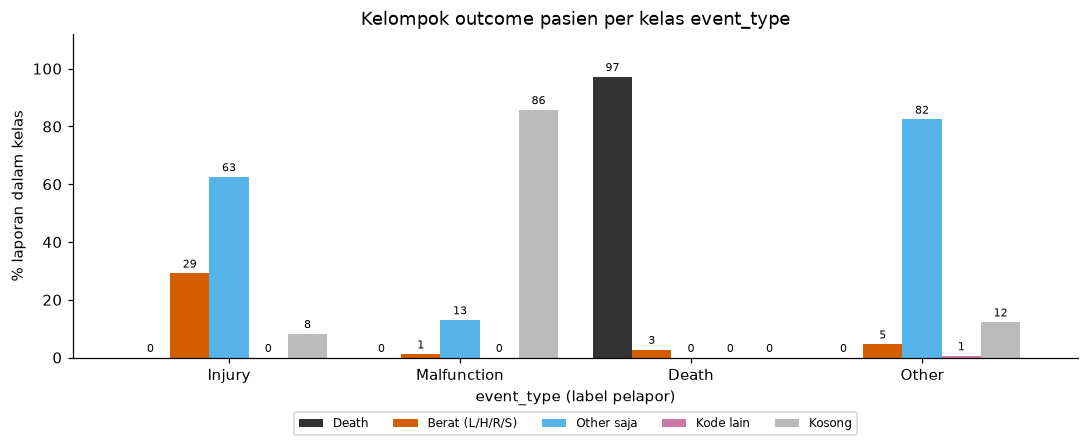

In [5]:
URUT = ["Death", "Berat (L/H/R/S)", "Other saja", "Kode lain", "Kosong"]
ox = pd.crosstab(d.label, d.outcome_grup).reindex(index=KELAS, columns=URUT, fill_value=0)
ox["Total"] = ox.sum(axis=1)
simpan_tab(ox, "09_outcome_x_event_type"); display(ox)
print(f"Death berlabel Death yang outcome-nya Death: {ox.loc['Death', 'Death']}/{ox.loc['Death', 'Total']}; "
      f"outcome Death di kelas lain: {ox.loc[['Injury', 'Malfunction', 'Other'], 'Death'].sum()}")
print(f"Malfunction tanpa outcome: {ox.loc['Malfunction', 'Kosong']}/{ox.loc['Malfunction', 'Total']}")

pr = ox[URUT].div(ox.Total, axis=0) * 100
fig, ax = plt.subplots(figsize=(10, 4.2))
pr.plot.bar(ax=ax, rot=0, width=0.85, color=["#333333", "#D55E00", "#56B4E9", "#CC79A7", "#BBBBBB"])
bar_labels(ax, fmt="{:.0f}", fontsize=7)
ax.set(ylabel="% laporan dalam kelas", xlabel="event_type (label pelapor)", title="Kelompok outcome pasien per kelas event_type")
ax.legend(fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.15)); ax.set_ylim(0, 112)
simpan_fig("09_outcome_x_event_type")

## 4. Inkonsistensi kode pelapor

Setiap pola diukur dengan dua definisi, supaya hasilnya tidak bergantung pada satu cara pencocokan:

| Pola | Definisi longgar | Definisi ketat |
|---|---|---|
| Malfunction dengan luka bakar | ada token `patient_problems` yang memuat substring `burn` | token cocok dengan kata utuh `\bburns?\b` |
| Injury tanpa dampak | minimal satu token "tanpa dampak" | **semua** token termasuk kategori tanpa dampak |
| Narasi menyebut kematian, kode bukan Death | — | `event_text` memuat died/death/dead/deceased/fatal/passed away/expired |

C:\Users\user\AppData\Local\Temp\ipykernel_32832\2703016872.py:9: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  d["narasi_mati"] = d.event_text.str.contains(MATI)


,pola,jumlah,dari,persen
0,Malfunction + luka bakar (longgar),89,1082,8.2
1,Malfunction + luka bakar (ketat),68,1082,6.3
2,Malfunction + outcome berat,13,1082,1.2
3,Injury + tanpa dampak (minimal satu),51,2144,2.4
4,Injury + tanpa dampak (semua token),41,2144,1.9
5,Injury/Malfunction/Other + narasi menyebut kem...,35,3568,1.0
6,Death + narasi tanpa penanda kematian,4,36,11.1


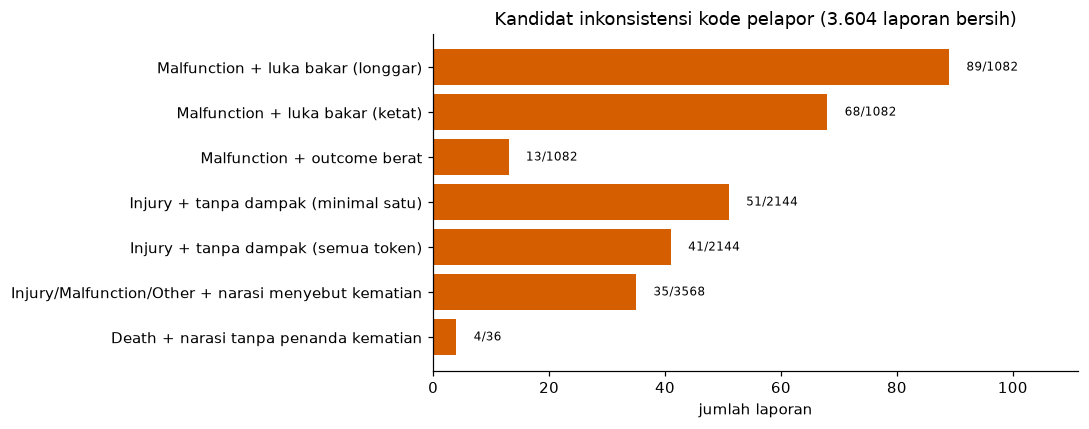

In [6]:
TANPA_DAMPAK = {"No Clinical Signs, Symptoms or Conditions", "No Known Impact Or Consequence To Patient",
                "No Consequences Or Impact To Patient", "No Patient Involvement"}
MATI = re.compile(r"\b(died|death|dead|deceased|fatal(ity)?|passed away|expired)\b", re.I)
tok = d.patient_problems.str.split(";").map(lambda t: [x for x in t if x])
d["burn_longgar"] = tok.map(lambda t: any("burn" in x.lower() for x in t))
d["burn_ketat"] = tok.map(lambda t: any(re.search(r"\bburns?\b", x, re.I) for x in t))
d["nodampak_satu"] = tok.map(lambda t: any(x in TANPA_DAMPAK for x in t))
d["nodampak_semua"] = tok.map(lambda t: bool(t) and all(x in TANPA_DAMPAK for x in t))
d["narasi_mati"] = d.event_text.str.contains(MATI)

baris = []
for nama, kelas, kol in [("Malfunction + luka bakar (longgar)", "Malfunction", "burn_longgar"),
                         ("Malfunction + luka bakar (ketat)", "Malfunction", "burn_ketat"),
                         ("Malfunction + outcome berat", "Malfunction", None),
                         ("Injury + tanpa dampak (minimal satu)", "Injury", "nodampak_satu"),
                         ("Injury + tanpa dampak (semua token)", "Injury", "nodampak_semua"),
                         ("Injury/Malfunction/Other + narasi menyebut kematian", None, "narasi_mati"),
                         ("Death + narasi tanpa penanda kematian", "Death", "narasi_mati")]:
    if kol is None:
        m = (d.label == kelas) & d.outcome_grup.eq("Berat (L/H/R/S)"); n = (d.label == kelas).sum()
    elif kelas is None:
        m = (d.label != "Death") & d[kol]; n = (d.label != "Death").sum()
    elif nama.startswith("Death"):
        m = (d.label == kelas) & ~d[kol]; n = (d.label == kelas).sum()
    else:
        m = (d.label == kelas) & d[kol]; n = (d.label == kelas).sum()
    baris.append(dict(pola=nama, jumlah=int(m.sum()), dari=int(n), persen=round(100 * m.sum() / n, 1)))
ink = simpan_tab(pd.DataFrame(baris), "09_inkonsistensi_kode", index=False); display(ink)

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(ink.pola[::-1], ink.jumlah[::-1], color="#D55E00")
for i, (j, n) in enumerate(zip(ink.jumlah[::-1], ink.dari[::-1])):
    ax.text(j + 3, i, f"{j}/{n}", va="center", fontsize=8)
ax.set(xlabel="jumlah laporan", title="Kandidat inkonsistensi kode pelapor (3.604 laporan bersih)")
ax.set_xlim(0, ink.jumlah.max() * 1.25)
simpan_fig("09_inkonsistensi_kode")

## 5. Apakah inkonsistensi kode menjelaskan kesalahan notebook 08?

Bagian ini membandingkan laporan test yang **salah** diprediksi dengan laporan test yang **benar** diprediksi dari kelas yang sama. Uji yang dipakai adalah uji eksak Fisher dua sisi. Jumlah kasusnya kecil, jadi hasil ini hanya bersifat eksploratif.

,kelompok_salah,penanda,salah_bertanda,benar_bertanda,persen_salah,persen_benar,p_fisher
0,Malfunction diprediksi Injury,luka bakar (ketat),7/19,3/124,36.8,2.4,0.000023
1,Malfunction diprediksi Injury,luka bakar (longgar),8/19,6/124,42.1,4.8,0.000040
2,Injury diprediksi Malfunction,tanpa dampak (semua token),1/10,3/314,10.0,1.0,0.120000
3,Injury diprediksi Malfunction,tanpa dampak (minimal satu),1/10,4/314,10.0,1.3,0.150000
4,Injury diprediksi Other,tanpa dampak (minimal satu),0/16,4/314,0.0,1.3,1.000000


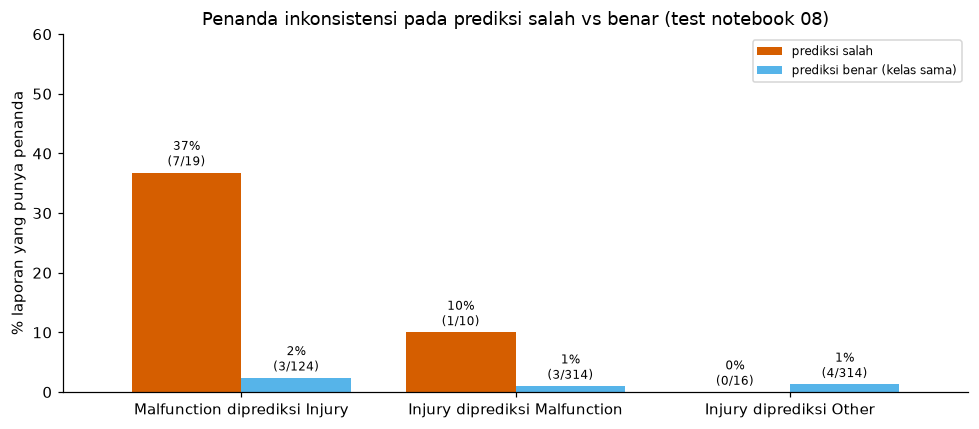

In [7]:
t = pred.merge(d, on="mdr_report_key", how="left", validate="one_to_one")
assert (t.y_true == t.label).all()
t["benar"] = t.y_true == t.y_pred
banding = [("Malfunction diprediksi Injury", "Malfunction", "Injury", "burn_ketat", "luka bakar (ketat)"),
           ("Malfunction diprediksi Injury", "Malfunction", "Injury", "burn_longgar", "luka bakar (longgar)"),
           ("Injury diprediksi Malfunction", "Injury", "Malfunction", "nodampak_semua", "tanpa dampak (semua token)"),
           ("Injury diprediksi Malfunction", "Injury", "Malfunction", "nodampak_satu", "tanpa dampak (minimal satu)"),
           ("Injury diprediksi Other", "Injury", "Other", "nodampak_satu", "tanpa dampak (minimal satu)")]
hasil = []
for nama, asli, pr_, kol, ket in banding:
    s = t[(t.y_true == asli) & (t.y_pred == pr_)]; b = t[(t.y_true == asli) & t.benar]
    a1, n1, a2, n2 = int(s[kol].sum()), len(s), int(b[kol].sum()), len(b)
    p = fisher_exact([[a1, n1 - a1], [a2, n2 - a2]])[1] if n1 and n2 else np.nan
    hasil.append(dict(kelompok_salah=nama, penanda=ket, salah_bertanda=f"{a1}/{n1}", benar_bertanda=f"{a2}/{n2}",
                      persen_salah=round(100 * a1 / n1, 1) if n1 else np.nan,
                      persen_benar=round(100 * a2 / n2, 1) if n2 else np.nan, p_fisher=float(f"{p:.2g}")))
kv = simpan_tab(pd.DataFrame(hasil), "09_kesalahan_vs_inkonsistensi", index=False); display(kv)

x = kv.drop_duplicates("kelompok_salah").set_index("kelompok_salah")
fig, ax = plt.subplots(figsize=(9, 4))
x[["persen_salah", "persen_benar"]].rename(columns={"persen_salah": "prediksi salah", "persen_benar": "prediksi benar (kelas sama)"}).plot.bar(
    ax=ax, rot=0, color=["#D55E00", "#56B4E9"], width=0.8)
for c, kolom in zip(ax.containers, ["salah_bertanda", "benar_bertanda"]):
    ax.bar_label(c, labels=[f"{v:.0f}%\n({s})" for v, s in zip(c.datavalues, x[kolom])], fontsize=8, padding=2)
ax.set(ylabel="% laporan yang punya penanda", xlabel="", title="Penanda inkonsistensi pada prediksi salah vs benar (test notebook 08)")
ax.set_ylim(0, max(60, x.persen_salah.max() * 1.35)); ax.legend(fontsize=8)
simpan_fig("09_kesalahan_vs_inkonsistensi")

## 6. Kelas Other: era dan isi kodenya

patient_problems teratas pada Other: [('Burn(s)', 102), ('Blister(s)', 98), ('Burn, Thermal', 50), ('Partial thickness (Second Degree) Burn', 50), ('Burning Sensation', 37), ('Erythema', 28), ('Pain', 21), ('Treatment with medication(s)', 21)]


,laporan Other (data bersih),Other di test,Other test diprediksi benar,recall_test
era,,,,
s.d. 2010,302,31,15,0.484
2011-2020,28,5,0,0.000
2021+,12,1,0,0.000


y_pred,Injury,Malfunction
era,,
2011-2020,1,4
2021+,0,1
s.d. 2010,14,2


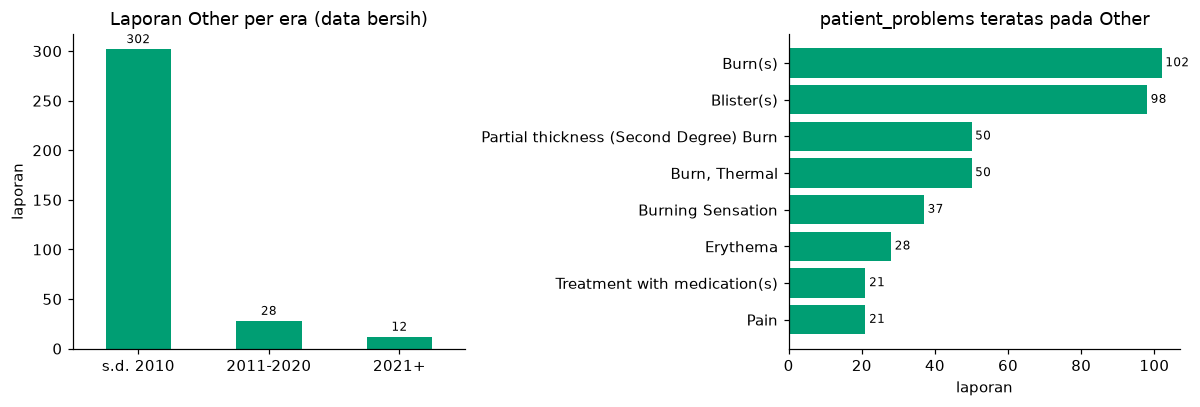

In [8]:
o = d[d.label == "Other"]
top_pp = collections.Counter(x for s in o.patient_problems for x in s.split(";") if x).most_common(8)
print("patient_problems teratas pada Other:", top_pp)
per_era = pd.DataFrame({"laporan Other (data bersih)": o.era.value_counts(),
                        "Other di test": t[t.y_true == "Other"].era.value_counts(),
                        "Other test diprediksi benar": t[(t.y_true == "Other") & t.benar].era.value_counts()}
                       ).reindex(["s.d. 2010", "2011-2020", "2021+"]).fillna(0).astype(int)
per_era["recall_test"] = (per_era["Other test diprediksi benar"] / per_era["Other di test"].replace(0, np.nan)).round(3)
salah_ke = t[(t.y_true == "Other") & ~t.benar].groupby("era").y_pred.value_counts().unstack(fill_value=0)
simpan_tab(per_era, "09_other_per_era"); display(per_era); display(salah_ke)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
per_era["laporan Other (data bersih)"].plot.bar(ax=axs[0], rot=0, color="#009E73"); bar_labels(axs[0])
axs[0].set(title="Laporan Other per era (data bersih)", ylabel="laporan", xlabel="")
pp = pd.Series(dict(top_pp)).sort_values()
axs[1].barh(pp.index, pp.values, color="#009E73")
for i, v in enumerate(pp.values):
    axs[1].text(v + 1, i, str(v), va="center", fontsize=8)
axs[1].set(title="patient_problems teratas pada Other", xlabel="laporan")
simpan_fig("09_other_per_era")

## 7. Kelas Death di test

Di sini dicek apakah informasi kematian ada di narasi, di kode outcome, atau di keduanya. Narasi diperiksa memakai `event_text` asli, karena `text_tf` sudah dimasking kata `death`.

In [9]:
dt = t[t.y_true == "Death"][["mdr_report_key", "tahun", "y_pred", "outcome_grup", "narasi_mati"]].rename(
    columns={"narasi_mati": "narasi_ada_penanda_kematian"})
simpan_tab(dt, "09_death_test", index=False); display(dt)
print("Death terlewat:", int((dt.y_pred != "Death").sum()), "| di antaranya narasi tanpa penanda kematian:",
      int(((dt.y_pred != "Death") & ~dt.narasi_ada_penanda_kematian).sum()))

,mdr_report_key,tahun,y_pred,outcome_grup,narasi_ada_penanda_kematian
15,297673,2000,Death,Death,True
19,334671,2001,Injury,Death,False
234,4339994,2014,Death,Death,True
261,5778348,2016,Injury,Death,True
263,5895839,2016,Death,Death,True
479,22644009,2025,Death,Death,True


Death terlewat: 2 | di antaranya narasi tanpa penanda kematian: 1


## 8. Daftar telaah buta

Kandidat diambil dari pola inkonsistensi bagian 4. Kontrolnya adalah laporan tanpa penanda dari kelas yang sama, diambil acak dengan seed 42.

**Prediksi model dan alasan terpilihnya laporan disembunyikan** di file kunci terpisah. Dengan begitu, penelaah tidak terpengaruh oleh model. Penelaah cukup mengisi kolom `keputusan` dengan salah satu pilihan: label cocok, label meragukan, atau label tampak salah.

In [10]:
syarat = {
    "Malfunction + luka bakar (ketat)": (d.label == "Malfunction") & d.burn_ketat,
    "Malfunction + outcome berat": (d.label == "Malfunction") & d.outcome_grup.eq("Berat (L/H/R/S)"),
    "Injury + tanpa dampak (semua token)": (d.label == "Injury") & d.nodampak_semua,
    "non-Death + narasi menyebut kematian": (d.label != "Death") & d.narasi_mati,
    "Death + outcome bukan Death": (d.label == "Death") & d.outcome_grup.ne("Death"),
}
d["alasan_kandidat"] = ""
for k, m in syarat.items():
    d.loc[m, "alasan_kandidat"] = d.loc[m, "alasan_kandidat"].str.cat([k] * m.sum(), sep="; ").str.strip("; ")
kand = d[d.alasan_kandidat != ""]
kontrol = pd.concat([d[(d.label == k) & (d.alasan_kandidat == "")].sample(min(n, 10), random_state=SEED)
                     for k, n in kand.label.value_counts().items()])
tl = pd.concat([kand.assign(jenis="kandidat"), kontrol.assign(jenis="kontrol")]).sample(frac=1, random_state=SEED)
tl["id_telaah"] = [f"T{i:03d}" for i in range(1, len(tl) + 1)]
tl = tl.merge(t[["mdr_report_key", "y_pred"]], on="mdr_report_key", how="left")
TERJ = pd.read_csv(ROOT / "data/processed/terjemahan_narasi_id.csv", dtype=str).set_index("mdr_report_key").narasi_id
buta = tl[["id_telaah", "mdr_report_key", "era", "label", "outcome", "patient_problems", "event_text"]].assign(
    event_text=tl.event_text.str[:700], keputusan="", catatan="")
buta.insert(buta.columns.get_loc("event_text"), "narasi_id", buta.mdr_report_key.map(TERJ))
assert buta.narasi_id.notna().all(), "ada narasi telaah tanpa terjemahan"
kunci = tl[["id_telaah", "mdr_report_key", "jenis", "alasan_kandidat", "y_pred"]].rename(columns={"y_pred": "prediksi_nb08_bila_di_test"})
simpan_tab(buta, "09_telaah_buta", index=False, encoding="utf-8-sig"); simpan_tab(kunci, "09_telaah_kunci", index=False, encoding="utf-8-sig")
print("kandidat:", len(kand), "| kontrol:", len(kontrol), "| total telaah:", len(tl))
display(kand.alasan_kandidat.str.split("; ").explode().value_counts().rename("jumlah").to_frame())
display(pd.crosstab(kand.era, kand.label))

kandidat: 152 | kontrol: 21 | total telaah: 173


,jumlah
alasan_kandidat,
Malfunction + luka bakar (ketat),68
Injury + tanpa dampak (semua token),41
non-Death + narasi menyebut kematian,35
Malfunction + outcome berat,13
Death + outcome bukan Death,1


label,Death,Injury,Malfunction
era,,,
2011-2020,0,22,20
2021+,1,34,28
s.d. 2010,0,4,43


### 8b. Analisis kesalahan notebook 08 dalam bahasa Indonesia

Narasi MAUDE ditulis dalam bahasa Inggris, umumnya huruf kapital semua. Supaya telaah lebih mudah, cuplikan narasi di tabel kesalahan notebook 08 (`15_prediksi_salah.csv`, 77 laporan) dan di daftar telaah buta (173 laporan) diberi kolom terjemahan `narasi_id`.

- **Sumber terjemahan:** `data/processed/terjemahan_narasi_id.csv` (237 narasi unik).
- **Penerjemah:** Claude (asisten AI). Terjemahan **belum ditelaah manusia**.
- **Aturan:** teks asli Inggris tetap disimpan dan tetap menjadi acuan. Terjemahan hanya alat bantu baca; terjemahan tidak dipakai untuk melatih atau menilai model.
- **Penanda dalam terjemahan:** narasi yang terpotong diakhiri "…", dan tanda (B)(4)/(B)(6) adalah sensor FDA.

In [11]:
salah = pd.read_csv(ROOT / "outputs/nb08/tables/15_prediksi_salah.csv", dtype=str, keep_default_na=False)
salah.insert(salah.columns.get_loc("cuplikan"), "narasi_id", salah.mdr_report_key.map(TERJ))
assert salah.narasi_id.notna().all(), "ada kesalahan notebook 08 tanpa terjemahan"
salah = salah.rename(columns={"cuplikan": "cuplikan_en"})
simpan_tab(salah, "09_prediksi_salah_nb08_id", index=False, encoding="utf-8-sig")
print("kesalahan notebook 08 dengan terjemahan:", len(salah))
with pd.option_context("display.max_colwidth", 220):
    display(salah[["mdr_report_key", "label", "prediksi", "alasan", "narasi_id"]].head(8))

kesalahan notebook 08 dengan terjemahan: 77


,mdr_report_key,label,prediksi,alasan,narasi_id
0,10240652,Malfunction,Injury,"Ada cedera/luka bakar, dikode Malfunction",Siemens diberi tahu tentang insiden yang terjadi pada sistem MAGNETOM Sola. Pasien diposisikan dengan kepala masuk lebih dulu di meja dan telah menyelesaikan pemeriksaan tulang belakang leher dan toraks. Saat pasien ...
1,18570131,Malfunction,Injury,"Ada cedera/luka bakar, dikode Malfunction",Siemens Healthineers diberi tahu bahwa seorang pasien mengalami cedera dengan tingkat keparahan yang belum diketahui selama pemeriksaan MRI perlekatan hamstring bilateral dengan sistem MAGNETOM Sola. Siemens Healthin...
2,12224411,Malfunction,Injury,"Ada cedera/luka bakar, dikode Malfunction","Pasien menjalani MRI otak, dasar tengkorak, dan leher. Pemindaian berlangsung 1,5–2 jam. Pasien memiliki alat pacu jantung dan tato di lehernya. Di akhir pemindaian, pasien memiliki [luka] berbentuk oval sekitar 4 c…"
3,681260,Malfunction,Injury,"Ada cedera/luka bakar, dikode Malfunction","Saat menjalani pemindaian tulang belakang, pasien mengalami luka bakar. Pemindaian lumbal dimulai dan pasien melaporkan rasa terbakar. Pemindaian segera dihentikan dan diperiksa. Area 2–3 inci tampak eritema (kemerah..."
4,2847822,Malfunction,Injury,"Ada cedera/luka bakar, dikode Malfunction","Peralatan: MRI GE 1.5 Tesla HDxt 16 kanal. Pasien menjalani MRI lumbal. Pasien memiliki pelat dan sekrup bedah di humerus proksimal, dengan pelat di sisi lateral. Selama MRI pasien melaporkan nyeri lengan. Pasien mel..."
5,16775482,Malfunction,Injury,"Ada cedera/luka bakar, dikode Malfunction","Luka bakar di kedua tangan setelah MRI. Pasien perempuan lanjut usia dengan riwayat diabetes dan limfedema kronis menjalani MRI kaki pada [tanggal disamarkan]. Saat kontrol, dokternya menemukan luka bakar di punggung..."
6,23821783,Malfunction,Injury,"Ada cedera/luka bakar, dikode Malfunction","Kacamata sistem video MRI bertumpu di wajah/hidung pasien, dan pasien mengalami luka bakar termal akibat kacamata itu. Kacamata sebagian terlepas dari wajahnya ketika meja bergerak sehingga posisinya miring, dan bagi..."
7,23254998,Malfunction,Injury,"Ada cedera/luka bakar, dikode Malfunction","Siemens Healthineers diberi tahu tentang kemungkinan cedera pasien yang melibatkan MAGNETOM Aera. Menurut informasi dari pelanggan, pasien melaporkan luka bakar di pahanya selama pemeriksaan. Siemens Healthineers tid..."


## 9. Diagnostik metadata: apakah kolom non-narasi bisa menjadi fitur?

Model yang dipakai adalah LR dengan bobot kelas di atas one-hot (kategori dengan kurang dari 5 laporan digabung). Encoder **dipelajari hanya dari train**. Ada dua skema evaluasi:

- **5-fold per grup:** memakai kolom `fold` dari notebook 02 (0 grup menyeberang).
- **Temporal:** train sampai 2020, uji 2021 ke atas. Laporan uji yang grupnya juga muncul di train dibuang.

Sebagai pembanding pada skema yang sama, dipakai **narasi** (TF-IDF kata + LR pada `text_clean`). Angka di bagian ini tidak bisa dibandingkan langsung dengan test notebook 08, karena partisinya berbeda.

,fitur,macro_f1_5fold,sd_5fold,death_benar_5fold,macro_f1_temporal,death_benar_temporal,n_uji_temporal
0,indikator hilang saja,0.429,0.011,0/36,0.408,0/10,1312
1,umur + jenis kelamin,0.342,0.010,8/36,0.428,1/10,1312
2,enam metadata,0.409,0.015,11/36,0.428,1/10,1312
3,era saja,0.335,0.067,3/36,0.164,0/10,1312
4,enam metadata + era,0.439,0.019,12/36,0.425,1/10,1312
5,narasi (TF-IDF + LR),0.667,0.057,10/36,0.567,2/10,1312


uji temporal per kelas: {'Injury': 648, 'Malfunction': 642, 'Other': 12, 'Death': 10}


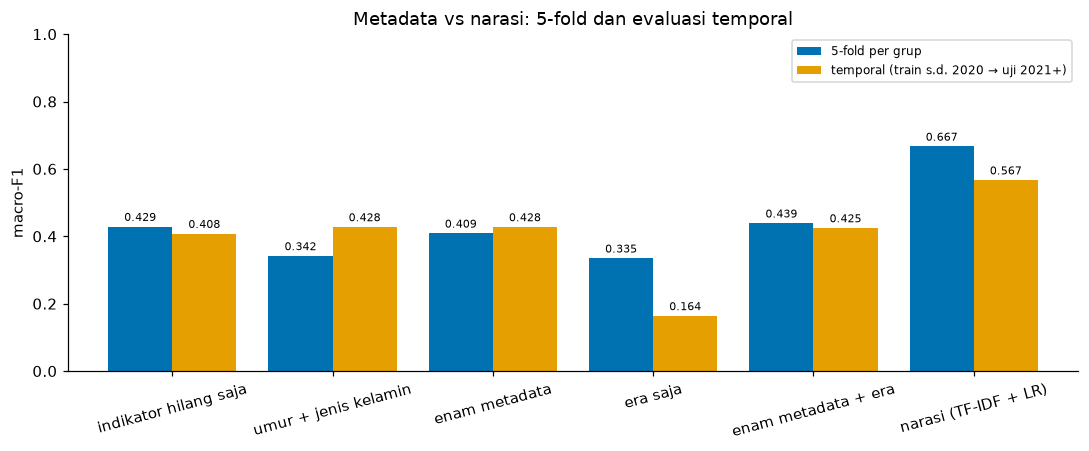

In [12]:
def umur_bin(s):
    m = re.match(r"^(\d+(?:\.\d+)?)\s*([A-Za-z]+)", s)
    if not m: return "tidak ada"
    v, u = float(m.group(1)), m.group(2).upper()
    th = v if u.startswith("Y") else v / 12 if u.startswith("M") else 0
    return "<18" if th < 18 else "18-39" if th < 40 else "40-59" if th < 60 else "60+"


d["umur_bin"] = d.patient_age.map(umur_bin)
d["sex_n"] = np.where(d.patient_sex.isin(["Female", "Male"]), d.patient_sex, "tidak ada")
for k in ["event_location", "reporter_occupation", "report_source", "device_operator"]:
    d[k + "_n"] = np.where(terisi(d[k], k), d[k], "tidak ada")
d["hilang"] = (d.umur_bin.eq("tidak ada").astype(int).astype(str) + d.sex_n.eq("tidak ada").astype(int).astype(str)
               + d.event_location_n.eq("tidak ada").astype(int).astype(str))
ENAM = ["umur_bin", "sex_n", "event_location_n", "reporter_occupation_n", "report_source_n", "device_operator_n"]
SET = {"indikator hilang saja": ["hilang"], "umur + jenis kelamin": ["umur_bin", "sex_n"],
       "enam metadata": ENAM, "era saja": ["era"], "enam metadata + era": ENAM + ["era"], "narasi (TF-IDF + LR)": None}


def latih_uji(kol, tr, te):
    if kol is None:
        v = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, stop_words="english")
        Xtr, Xte = v.fit_transform(tr.text_clean), v.transform(te.text_clean)
    else:
        enc = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5)
        Xtr, Xte = enc.fit_transform(tr[kol]), enc.transform(te[kol])
    m = LogisticRegression(class_weight="balanced", max_iter=3000, C=1.0 if kol else 10).fit(Xtr, tr.label)
    return m.predict(Xte)


baris = []
for nama, kol in SET.items():
    skor, mati_benar = [], 0
    for f in range(5):
        tr, te = d[d.fold != f], d[d.fold == f]
        p = latih_uji(kol, tr, te)
        skor.append(f1_score(te.label, p, labels=KELAS, average="macro", zero_division=0))
        mati_benar += int(((te.label == "Death") & (p == "Death")).sum())
    tr = d[d.tahun <= 2020]; te = d[(d.tahun >= 2021) & ~d.grup.isin(tr.grup)]
    p = latih_uji(kol, tr, te)
    baris.append(dict(fitur=nama, macro_f1_5fold=round(np.mean(skor), 3), sd_5fold=round(np.std(skor, ddof=1), 3),
                      death_benar_5fold=f"{mati_benar}/{(d.label == 'Death').sum()}",
                      macro_f1_temporal=round(f1_score(te.label, p, labels=KELAS, average="macro", zero_division=0), 3),
                      death_benar_temporal=f"{int(((te.label == 'Death') & (p == 'Death')).sum())}/{int((te.label == 'Death').sum())}",
                      n_uji_temporal=len(te)))
dm = simpan_tab(pd.DataFrame(baris), "09_diagnostik_metadata", index=False); display(dm)
print("uji temporal per kelas:", te.label.value_counts().to_dict())

fig, ax = plt.subplots(figsize=(10, 4.2))
dm.set_index("fitur")[["macro_f1_5fold", "macro_f1_temporal"]].rename(
    columns={"macro_f1_5fold": "5-fold per grup", "macro_f1_temporal": "temporal (train s.d. 2020 → uji 2021+)"}).plot.bar(
    ax=ax, rot=15, color=["#0072B2", "#E69F00"], width=0.8)
bar_labels(ax, fmt="{:.3f}", fontsize=7)
ax.set(ylabel="macro-F1", xlabel="", title="Metadata vs narasi: 5-fold dan evaluasi temporal"); ax.set_ylim(0, 1)
ax.legend(fontsize=8)
simpan_fig("09_diagnostik_metadata")

## 10. Kontrol positif kebocoran (bukan skor resmi)

Bagian ini membandingkan narasi saja dengan narasi ditambah one-hot `outcome_grup`, memakai 5-fold yang sama. Tujuannya **hanya memperlihatkan** seberapa besar skor akan naik bila kolom yang diisi bersama label ikut dimasukkan. Angka ini tidak boleh dilaporkan sebagai kinerja model.

,input,macro_f1_5fold,sd,death_benar
0,narasi saja,0.667,0.057,10/36
1,narasi + outcome (BOCOR),0.846,0.027,35/36


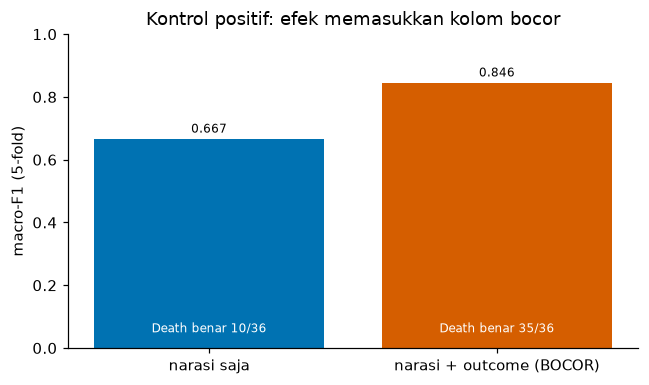

In [13]:
baris = []
for nama, pakai in [("narasi saja", False), ("narasi + outcome (BOCOR)", True)]:
    skor, mati = [], 0
    for f in range(5):
        tr, te = d[d.fold != f], d[d.fold == f]
        v = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, stop_words="english")
        Xtr, Xte = v.fit_transform(tr.text_clean), v.transform(te.text_clean)
        if pakai:
            enc = OneHotEncoder(handle_unknown="ignore").fit(tr[["outcome_grup"]])
            Xtr = hstack([Xtr, enc.transform(tr[["outcome_grup"]]) * 3]).tocsr()
            Xte = hstack([Xte, enc.transform(te[["outcome_grup"]]) * 3]).tocsr()
        p = LogisticRegression(class_weight="balanced", max_iter=3000, C=10).fit(Xtr, tr.label).predict(Xte)
        skor.append(f1_score(te.label, p, labels=KELAS, average="macro", zero_division=0))
        mati += int(((te.label == "Death") & (p == "Death")).sum())
    baris.append(dict(input=nama, macro_f1_5fold=round(np.mean(skor), 3), sd=round(np.std(skor, ddof=1), 3),
                      death_benar=f"{mati}/{(d.label == 'Death').sum()}"))
kb = simpan_tab(pd.DataFrame(baris), "09_kontrol_kebocoran", index=False); display(kb)

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.bar(kb.input, kb.macro_f1_5fold, color=["#0072B2", "#D55E00"]); bar_labels(ax, fmt="{:.3f}")
for i, s in enumerate(kb.death_benar):
    ax.text(i, 0.05, f"Death benar {s}", ha="center", color="white", fontsize=8)
ax.set(ylabel="macro-F1 (5-fold)", ylim=(0, 1), title="Kontrol positif: efek memasukkan kolom bocor")
simpan_fig("09_kontrol_kebocoran")

## 11. Kesimpulan

In [14]:
r = lambda tb, i, k: tb.iloc[i][k]
teks = f"""
1. Kolom outcome, flag kejadian merugikan, dan flag masalah produk BOCOR LABEL: outcome Death muncul pada {ox.loc['Death', 'Death']}/{ox.loc['Death', 'Total']} laporan Death dan {ox.loc[['Injury', 'Malfunction', 'Other'], 'Death'].sum()} laporan kelas lain; {ox.loc['Malfunction', 'Kosong']}/{ox.loc['Malfunction', 'Total']} Malfunction tanpa outcome. Kolom ini dipakai untuk audit, bukan fitur.
2. Kontrol positif: narasi {r(kb, 0, 'macro_f1_5fold')} -> narasi + outcome {r(kb, 1, 'macro_f1_5fold')} (Death benar {r(kb, 0, 'death_benar')} -> {r(kb, 1, 'death_benar')}); kenaikan ini adalah kebocoran, bukan kemampuan model.
3. Inkonsistensi kode: {r(ink, 1, 'jumlah')}/{r(ink, 1, 'dari')} Malfunction punya kode luka bakar (ketat; longgar {r(ink, 0, 'jumlah')}), {r(ink, 4, 'jumlah')}/{r(ink, 4, 'dari')} Injury hanya berkode tanpa dampak, {r(ink, 5, 'jumlah')} laporan non-Death menyebut kematian di narasi.
4. Kesalahan notebook 08: luka bakar (ketat) ada pada {r(kv, 0, 'salah_bertanda')} Malfunction yang diprediksi Injury vs {r(kv, 0, 'benar_bertanda')} yang benar (Fisher p={r(kv, 0, 'p_fisher')}). Sebagian kesalahan model adalah laporan berkode tidak konsisten.
5. Other: recall test {per_era['recall_test'].to_dict()} per era; kode masalah pasien teratas adalah luka bakar/lepuh, jadi Other lama berisi laporan bergaya cedera.
6. Metadata: enam metadata {r(dm, 2, 'macro_f1_5fold')} (5-fold) / {r(dm, 2, 'macro_f1_temporal')} (temporal), jauh di bawah narasi {r(dm, 5, 'macro_f1_5fold')} / {r(dm, 5, 'macro_f1_temporal')}. Era saja turun dari {r(dm, 3, 'macro_f1_5fold')} ke {r(dm, 3, 'macro_f1_temporal')} saat diuji di era baru (jalan pintas yang tidak berpindah), dan indikator kolom kosong saja sudah memberi {r(dm, 0, 'macro_f1_5fold')}: kelengkapan formulir berbeda antarkelas. Metadata tidak dijadikan fitur model utama.
7. Daftar telaah buta: {len(kand)} kandidat + {len(kontrol)} kontrol; prediksi model disembunyikan di file kunci. Ketidakcocokan kode adalah alasan untuk menelaah, bukan bukti salah label.
"""
print(teks)
(TAB / "09_kesimpulan.txt").write_text(teks.strip(), encoding="utf-8")


1. Kolom outcome, flag kejadian merugikan, dan flag masalah produk BOCOR LABEL: outcome Death muncul pada 35/36 laporan Death dan 0 laporan kelas lain; 928/1082 Malfunction tanpa outcome. Kolom ini dipakai untuk audit, bukan fitur.
2. Kontrol positif: narasi 0.667 -> narasi + outcome 0.846 (Death benar 10/36 -> 35/36); kenaikan ini adalah kebocoran, bukan kemampuan model.
3. Inkonsistensi kode: 68/1082 Malfunction punya kode luka bakar (ketat; longgar 89), 41/2144 Injury hanya berkode tanpa dampak, 35 laporan non-Death menyebut kematian di narasi.
4. Kesalahan notebook 08: luka bakar (ketat) ada pada 7/19 Malfunction yang diprediksi Injury vs 3/124 yang benar (Fisher p=2.3e-05). Sebagian kesalahan model adalah laporan berkode tidak konsisten.
5. Other: recall test {'s.d. 2010': 0.484, '2011-2020': 0.0, '2021+': 0.0} per era; kode masalah pasien teratas adalah luka bakar/lepuh, jadi Other lama berisi laporan bergaya cedera.
6. Metadata: enam metadata 0.409 (5-fold) / 0.428 (temporal), 

1436